# Proyecto 1 — EEG con parpadeos reales (Eye-BCI): sacar el EOG con NLMS

**Cómo leer este notebook:** igual que `proyecto1_g4.ipynb`. Cada sección empieza con un recuadro **"Dónde estamos"**. Antes de cada celda de código hay un bloque que dice qué hace y por qué. Debajo de cada gráfico o tabla hay un **"Qué mirar"** con lo que se ve y los números medidos.

---

## Por qué otro dataset
En ds008701 el EEG venía **preprocesado**: le habían sacado los parpadeos. El ruido de ojos que quedaba era chico (movimientos horizontales), así que no podíamos probar el filtro contra el ruido de ojos más importante.

**Eye-BCI** (Guttmann-Flury, Sheng & Zhu 2025, *Scientific Data*, DOI 10.1038/s41597-025-04861-9; copia en Zenodo, DOI 10.5281/zenodo.18971758) es **EEG crudo**, con:
- parpadeos reales en el EEG;
- un canal de EOG medido (`HEO`);
- una columna `Blinks` que marca el pico de cada parpadeo (los autores los detectaron con video y con el EEG). **Esto es lo nuevo: sabemos dónde están los parpadeos sin detectarlos nosotros.**

Usamos un solo archivo: sujeto 1, sesión 1 (`ME011`). La tarea es de **ejecución motora**: 40 repeticiones de "mirar una cruz 2 s → agarrar con la mano izquierda o derecha 4 s → descansar 1–1.5 s".

## El modelo (el mismo de antes, pero solo con EOG)
Lo que mide un electrodo:

`y(n) = s(n) + λ·η_EOG(n)`

- `s(n)`: el EEG, lo que queremos.
- `η_EOG(n)`: el ruido de los ojos. `λ` dice cuánto llega a ese electrodo.

La referencia es el canal `HEO`, y el filtro FIR la convierte en "el parpadeo tal como llega al electrodo":

`x(n) = [HEO(n), HEO(n−1), HEO(n−2)]ᵀ`,  `ŷ(n) = wᵀ(n) x(n)`,  `e(n) = y(n) − ŷ(n) ≈ s(n)`

```
 s(n) EEG ───────────────────┐
 η_EOG ──λ───────────────────┼──►  y(n)  (electrodo)
                             │       │
 x(n) = HEO ──► [ w ] ── ŷ(n) ──────►(−)──► e(n) = y − ŷ ≈ s(n)
                  ▲                          │
                  └─────── NLMS ◄────────────┘
```

**Dos decisiones de arranque:**
- **Solo una referencia, el EOG.** El archivo no tiene canal de EMG. El EMG se discute después de ver los resultados.
- **Solo NLMS.** VS-LMS y la compuerta de §8 del notebook anterior salieron de conocer *esa* señal. Acá primero miramos qué hace NLMS tal cual.

## Mapa del notebook

| Sección | Pregunta que responde |
|---|---|
| §1 Carga | ¿Cómo leo el `.bdf` y el `_sync.csv`, y cómo los pongo en el mismo reloj? |
| §2 Inspección | ¿Qué ruido hay realmente? ¿Cuánto parpadeo llega a cada canal? ¿`HEO` sirve de referencia? |
| §3 El filtro | NLMS y Wiener, chequeos de cordura y una primera corrida sobre los datos reales. |

Después de §3 frenamos para discutir cómo seguir.

## §1. Carga

> **Dónde estamos:** antes de filtrar hay que leer tres archivos y ponerlos en el mismo reloj.
> - `ME011.bdf`: el EEG. BDF es el formato de BioSemi: como EDF, pero con muestras de 24 bits. MNE lo lee con `read_raw_bdf`.
> - `ME011_sync.csv`: una fila por milisegundo. Trae la columna `Blinks` (1 = pico de parpadeo) y `Cues` (en qué parte de la tarea está).
> - `ME011_annotations.json`: el cronograma de cada repetición. Lo usamos solo para chequear.
>
> Pasos: parámetros → carga y alineación → chequeo de lo que se cargó.

### 1.1 Parámetros
- **`FS = 250`:** bajamos de 1000 a 250 Hz, como antes. Todo lo que nos importa (EEG y EOG) está por debajo de ~40 Hz, y el filtro corre 4 veces más rápido.
- **`T_INI, T_FIN = 2, 338`:** la tarea termina a los ~338 s, pero la grabación sigue hasta los 452 s. En ese final la señal se rompe: el desvío de los canales pasa de ~30 µV a ~700 µV (probablemente la persona se mueve). Los primeros 2 s se sacan por el transitorio del pasa-altos.
- **`F_HP = 0.5`:** el `.bdf` viene sin filtrar (la cabecera dice pasa-altos 0 Hz), con continua y derivas de miles de µV. **El mismo pasa-altos se aplica a todos los canales, a `y` y a `x` por igual.** Si filtrás distinto la deseada y la referencia, cambiás el camino que el filtro tiene que aprender.
- **`CANALES_MALOS`:** los 11 canales que el artículo declara defectuosos o puenteados. No los usamos. Ojo: incluye `Oz`, el canal que usábamos antes como "EEG limpio".

In [1]:
import json
import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, lfilter, welch, correlate

mne.set_log_level("ERROR")

# Parámetros
RAIZ = "./datasets-presentacion-PASA/Sess01"
ARCHIVO = "ME011"           # Sujeto 01, sesión 1
FS_ORIG = 1000              # fs del .bdf [Hz]
FS = 250                    # Submuestreo 1000 -> 250 Hz
T_INI, T_FIN = 2, 338       # Ventana útil [s]: la tarea termina a los ~338 s y después la señal se rompe
F_HP = 0.5                  # Pasa-altos [Hz]: saca la continua y la deriva, igual en todos los canales
CANAL_EOG = "HEO"
CANALES_MALOS = ["PO3", "F1", "POz", "Oz", "F3", "O2", "P8", "PO7", "FC3", "P7", "P4"]  # Defectuosos según el artículo

### 1.2 Carga y alineación
`cargar()` hace lo mismo que en el notebook anterior: pasa-altos → submuestreo → recorte → µV → sin continua. Además, antes de descartar el canal `Trig`, lee de ahí cuándo empieza cada repetición.

Después lee `_sync.csv`:
- **Cómo se alinea:** la columna `Time` está en el mismo reloj que el `.bdf`. Por ejemplo, el primer `Fixation` está en `Time = 24.398` y el primer disparo del `.bdf` en la muestra 24 398. Entonces un parpadeo en `Time = t_p` es la muestra `(t_p − T_INI)·FS` de nuestras señales.
- **Sobran filas:** el `_sync.csv` tiene 560 filas más que el `.bdf` (452.56 s contra 452 s). Están al final, después de nuestro recorte, así que no molestan.
- **`Cues`** dice la fase de la tarea, pero viene salpicada: una etiqueta cada pocos ms y vacíos entre medio. Se completa hacia adelante y se traduce a fijación, ejecución (`Left`/`Right`), descanso (`Random`) y "otra" (bienvenida y despedida).

Por último, compara los `onset` de `_annotations.json` con los disparos del `.bdf`.

In [2]:
def cargar():
    """
    Carga el .bdf. Devuelve:
        datos: dict {canal: señal en µV}, con pasa-altos F_HP, submuestreada a FS y recortada a [T_INI, T_FIN]
        t_disparos: instantes [s] en que el canal Trig marca el comienzo de una repetición
        duracion: duración total del .bdf [s]
    """
    raw = mne.io.read_raw_bdf(f"{RAIZ}/{ARCHIVO}.bdf", preload=True, stim_channel=None)
    trig = raw.get_data(picks=["Trig"])[0]
    t_disparos = np.flatnonzero(np.diff(trig) > 0) / FS_ORIG   # Flancos de subida del disparo
    raw.drop_channels(["Trig"])               # El disparo no es una señal
    raw.filter(F_HP, None)                    # Mismo pasa-altos para y y para x
    raw.resample(FS)                          # MNE aplica el antialias
    raw.crop(T_INI, T_FIN)
    X = raw.get_data() * 1e6                  # V -> µV
    X = X - X.mean(axis=1, keepdims=True)     # Sin continua
    return dict(zip(raw.ch_names, X)), t_disparos, len(trig) / FS_ORIG


DATOS, t_disparos, DURACION = cargar()
N_MUESTRAS = len(DATOS[CANAL_EOG])
t = T_INI + np.arange(N_MUESTRAS) / FS        # Tiempo de cada muestra [s], en el reloj del .bdf

# _sync.csv: una fila por ms. Time es el tiempo en el reloj del .bdf
sync = pd.read_csv(f"{RAIZ}/{ARCHIVO}_sync.csv", usecols=["Time", "Cues", "Blinks"], dtype={"Cues": str})
t_parpadeos = sync["Time"].values[sync["Blinks"].values == 1]                     # Picos de parpadeo [s]
t_parpadeos = t_parpadeos[(t_parpadeos > T_INI) & (t_parpadeos < T_FIN)]           # Solo los del recorte
PARPADEOS = np.round((t_parpadeos - T_INI) * FS).astype(int)                       # Índices a FS

# Fase de la tarea en cada muestra: Cues viene salpicado cada pocos ms, se completa hacia adelante
NOMBRE_FASE = {"Welcome": "otra", "Goodbye": "otra", "Fixation": "fijación",
               "Left": "ejecución", "Right": "ejecución", "Random": "descanso"}
cues = sync["Cues"].ffill().fillna("Welcome").values
FASE = np.array([NOMBRE_FASE[c] for c in cues[np.searchsorted(sync["Time"].values, t)]])

# _annotations.json: cronograma de cada repetición, para comparar con los disparos del .bdf
anot = pd.DataFrame(json.load(open(f"{RAIZ}/{ARCHIVO}_annotations.json")))
onset_fijacion = anot.loc[anot["phase"] == "fixation", "onset"].values

print(f"{len(DATOS)} canales: {list(DATOS)}")
print(f"{N_MUESTRAS / FS:.0f} s a {FS} Hz (recorte {T_INI}-{T_FIN} s)")
print(f"_sync.csv: {len(sync)} filas = {sync['Time'].iloc[-1]:.2f} s; el .bdf dura {DURACION:.2f} s")
print(f"{len(t_disparos)} repeticiones; {len(PARPADEOS)} parpadeos marcados en el recorte "
      f"({len(PARPADEOS) / (N_MUESTRAS / FS) * 60:.1f} por minuto)")
print(f"annotations.json vs disparos del .bdf: onset - disparo = "
      f"{np.mean(onset_fijacion - t_disparos):.3f} ± {np.std(onset_fijacion - t_disparos):.3f} s")
print("Muestras por fase:", pd.Series(FASE).value_counts().to_dict())

65 canales: ['Fp1', 'Fpz', 'Fp2', 'AF3', 'AF4', 'F7', 'F5', 'F3', 'F1', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT7', 'FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'FT8', 'T7', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'T8', 'TP7', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 'TP8', 'P7', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO7', 'PO5', 'PO3', 'POz', 'PO4', 'PO6', 'PO8', 'O1', 'Oz', 'O2', 'CB1', 'CB2', 'M1', 'M2', 'HEO']
336 s a 250 Hz (recorte 2-338 s)
_sync.csv: 452560 filas = 452.56 s; el .bdf dura 452.00 s
40 repeticiones; 75 parpadeos marcados en el recorte (13.4 por minuto)
annotations.json vs disparos del .bdf: onset - disparo = -1.999 ± 0.000 s
Muestras por fase: {'ejecución': 42829, 'fijación': 21552, 'descanso': 14020, 'otra': 5600}


### Qué mirar: lo que se cargó
- **65 canales:**
  - 62 de EEG, con los nombres del sistema 10-20 (`Fp1`, `Fz`, `Pz`…), más `CB1` y `CB2`, sobre el cerebelo;
  - `M1` y `M2`: las mastoides, detrás de las orejas;
  - `HEO`.

  **No hay EOG vertical ni EMG**, aunque el artículo dice que los grabaron: en esta copia de Zenodo no están.
- **75 parpadeos en 336 s (13.4 por minuto).** En todo el archivo hay 105; los otros 30 caen en el final que recortamos.
- **40 repeticiones**, como dice el artículo.
- **`annotations.json` está corrido exactamente −2.000 s** respecto de los disparos del `.bdf`. Por eso usamos `Cues` del `_sync.csv`, que está en el reloj del `.bdf`, y no el `.json`.
- **Tiempo por fase:** la mitad es ejecución (171 s), un cuarto fijación (86 s), 56 s de descanso y 22 s de "otra".

## §2. Inspección

> **Dónde estamos:** ya tenemos las señales. Antes de filtrar hay que saber qué hay adentro: eso decide qué canal usar como `y`, si `HEO` sirve de referencia y qué esperar del filtro.
>
> Preguntas, en orden:
> 1. ¿Hay canales rotos? (tabla de desvíos)
> 2. ¿Cómo se ven los parpadeos? (señal en el tiempo)
> 3. ¿Cuánto parpadeo llega a cada canal? (promedio sincronizado)
> 4. ¿Cuánto vale `λ` en cada electrodo? (mapa)
> 5. ¿El camino ojo→electrodo tiene retardo? (correlación cruzada; decide `M`)
> 6. ¿Qué frecuencias hay? (PSD)
> 7. ¿`HEO` trae algo más que parpadeo? (fuga de EEG en la referencia)
> 8. ¿Hay ruido que no sea de los ojos? (parte común a todos los canales)
> 9. ¿Cuánta señal hay sin parpadeos? (insumo para un futuro semi-sintético)
> 10. ¿La tarea motora mete ruido? (desvío por fase)

### 2.1 ¿Hay canales rotos?
Calcula el desvío estándar de cada canal (después del pasa-altos y del recorte) y lo compara con la mediana de los canales buenos. Un canal desconectado da un desvío ~0; uno con mal contacto, muchas veces la mediana.

In [3]:
CANALES_EEG = [n for n in DATOS if n not in ["M1", "M2", CANAL_EOG]]
CANALES_BUENOS = [n for n in CANALES_EEG if n not in CANALES_MALOS]

desvio = pd.Series({n: DATOS[n].std() for n in DATOS})
mediana = desvio[CANALES_BUENOS].median()
tabla = pd.DataFrame({"std [µV]": desvio, "std / mediana": desvio / mediana,
                      "malo según el artículo": [n in CANALES_MALOS for n in desvio.index]})

print(f"{len(CANALES_EEG)} canales de EEG, {len(CANALES_BUENOS)} buenos. Mediana del std de los buenos: {mediana:.1f} µV\n")
print("Los 8 con más std:\n", tabla.sort_values("std [µV]", ascending=False).head(8).round(2).to_string(), "\n")
print("Los 5 con menos std:\n", tabla.sort_values("std [µV]").head(5).round(2).to_string(), "\n")
print("Los declarados malos:\n", tabla.loc[CANALES_MALOS].round(2).to_string())

62 canales de EEG, 51 buenos. Mediana del std de los buenos: 22.9 µV

Los 8 con más std:
      std [µV]  std / mediana  malo según el artículo
M1     437.98          19.09                   False
M2     233.02          10.16                   False
HEO     64.65           2.82                   False
Fpz     34.76           1.52                   False
Fp2     34.59           1.51                   False
Fp1     33.40           1.46                   False
AF3     31.58           1.38                   False
CPz     27.49           1.20                   False 

Los 5 con menos std:
      std [µV]  std / mediana  malo según el artículo
T8      14.70           0.64                   False
FT8     15.02           0.65                   False
TP8     15.05           0.66                   False
C6      15.14           0.66                   False
F8      15.23           0.66                   False 

Los declarados malos:
      std [µV]  std / mediana  malo según el artículo
PO3     23.77

### Qué mirar: desvío por canal
- **Los canales de EEG andan parecido:** entre 15 y 35 µV, con mediana 22.9 µV. Los más grandes son los frontales (`Fp1`, `Fpz`, `Fp2`, `AF3`: ~1.5 veces la mediana), que es adonde más llega el parpadeo.
- **Los 11 "malos" del artículo no se distinguen por el desvío** (0.7 a 1.1 veces la mediana). El artículo dice que están *puenteados*: dos electrodos en corto por el gel. Eso no se ve en el desvío, se ve en que dos canales vecinos son casi iguales. Les creemos y no los usamos.
- **`M1` y `M2` son enormes:** 438 y 233 µV, 10 a 20 veces el EEG. Según el artículo, `M1` es la referencia, así que debería ser ~0. No sabemos qué se grabó en esos dos canales, y no los usamos.
- **`HEO` tiene 65 µV**, casi 3 veces el EEG. Es lo esperable para un canal pegado al ojo.

### 2.2 Los parpadeos a simple vista
Dibuja 60 s (de 30 a 90 s) de estos canales:
- `HEO`;
- los frontales `Fp1` y `Fp2`;
- los laterales de adelante `F7` y `F8`;
- uno de atrás, `Pz`;
- uno del costado, `T7`.

Las líneas rojas son los parpadeos que marca `Blinks`. En naranja, los 4 s de ejecución del movimiento.

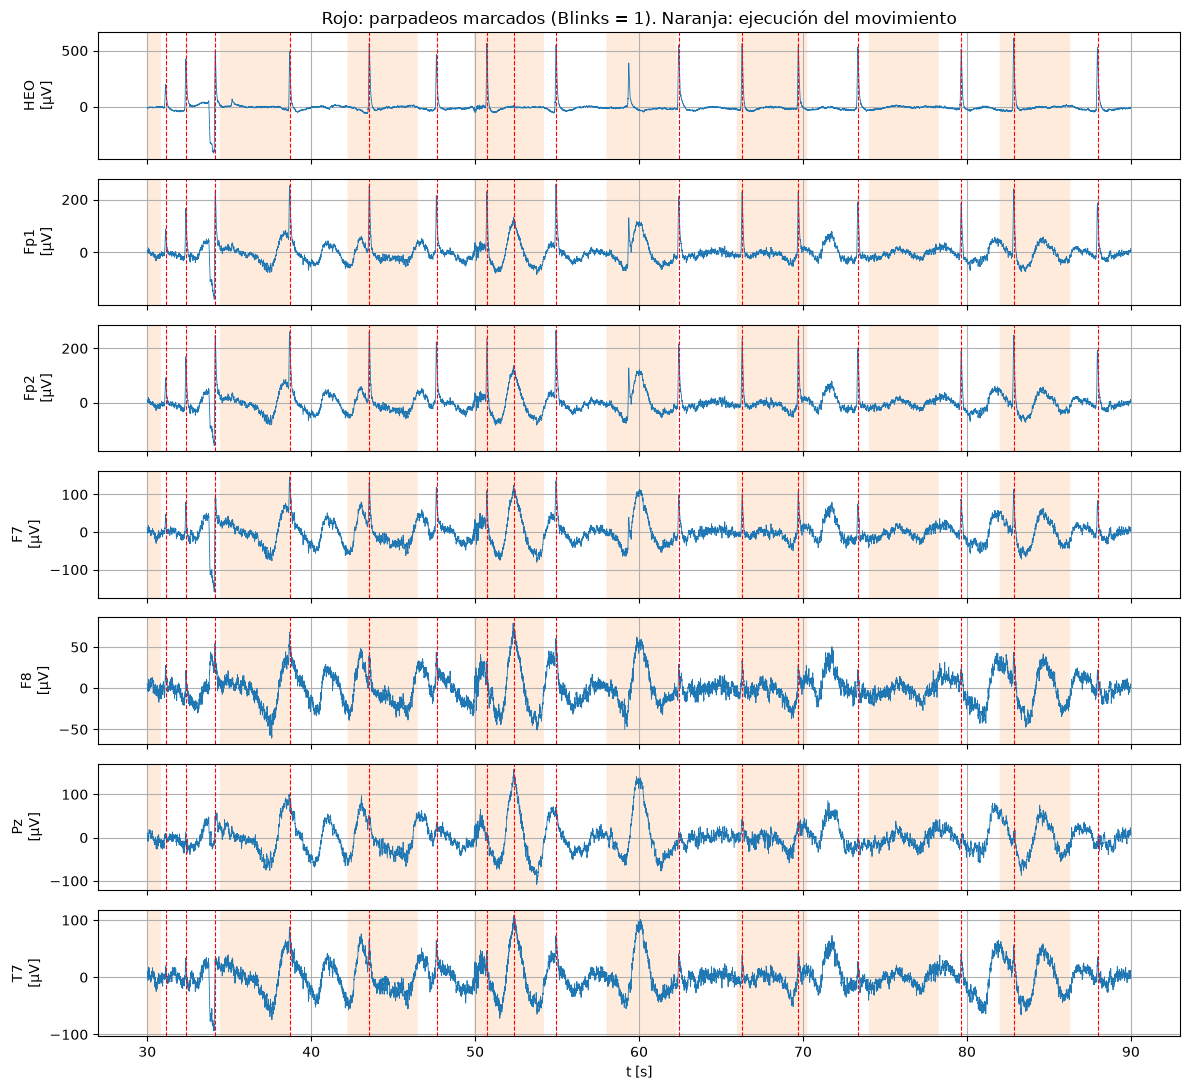

In [4]:
CANALES_VER = [CANAL_EOG, "Fp1", "Fp2", "F7", "F8", "Pz", "T7"]
T_VER = (30, 90)                                   # Tramo a mirar [s]

i0, i1 = [int((tv - T_INI) * FS) for tv in T_VER]
fig, axs = plt.subplots(len(CANALES_VER), 1, figsize=(12, 11), sharex=True)
for ax, n in zip(axs, CANALES_VER):
    ax.plot(t[i0:i1], DATOS[n][i0:i1], lw=0.6)
    ax.fill_between(t[i0:i1], 0, 1, where=FASE[i0:i1] == "ejecución", transform=ax.get_xaxis_transform(),
                    color="tab:orange", alpha=0.15, lw=0)
    for k in PARPADEOS[(PARPADEOS >= i0) & (PARPADEOS < i1)]:
        ax.axvline(t[k], color="r", lw=0.8, ls="--")
    ax.set_ylabel(f"{n}\n[µV]")
    ax.grid(True)
axs[0].set_title("Rojo: parpadeos marcados (Blinks = 1). Naranja: ejecución del movimiento")
axs[-1].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

### Qué mirar: los parpadeos en el tiempo
- **Cada línea roja cae sobre un pico:** en `HEO` de ~250 a ~550 µV, en `Fp1` y `Fp2` de ~200 µV, y más chico en `F7`. **La columna `Blinks` está bien alineada con el `.bdf`.**
- **Los picos son angostos:** ~0.2 s, lo que dice el artículo.
- **`HEO` sirve como referencia del parpadeo.** El nombre sugiere EOG *horizontal* (ojos a los costados), y el parpadeo es sobre todo vertical. Igual `HEO` muestra los parpadeos clarísimos. Hay alguna deflexión que no es parpadeo (por ejemplo, −150 µV a los 34 s): puede ser un movimiento de ojos.
- **Lo inesperado: ondas lentas de ~100 µV y ~1 s en *todos* los canales de EEG**, incluidos `Pz` y `T7`, sobre todo durante la ejecución (naranja). **En `HEO` no están.** No son de los ojos: si lo fueran, serían más grandes adelante que atrás y estarían en `HEO`. Se estudian en 2.8.

### 2.3 Cuánto parpadeo llega a cada canal
El mismo truco que en el notebook anterior (`proyecto1_g4.ipynb`, §2):
1. recortar ±1 s alrededor de cada parpadeo;
2. promediar todos los recortes.

Lo que está atado al parpadeo se suma en todos los recortes. El EEG no tiene nada que ver con el parpadeo, así que en el promedio tiende a 0.

**La diferencia con antes:** ahora los eventos los marca el dataset (`Blinks`), no los detectamos nosotros sobre el EOG, y son 75 en lugar de 6. Los canales van ordenados de adelante hacia atrás.

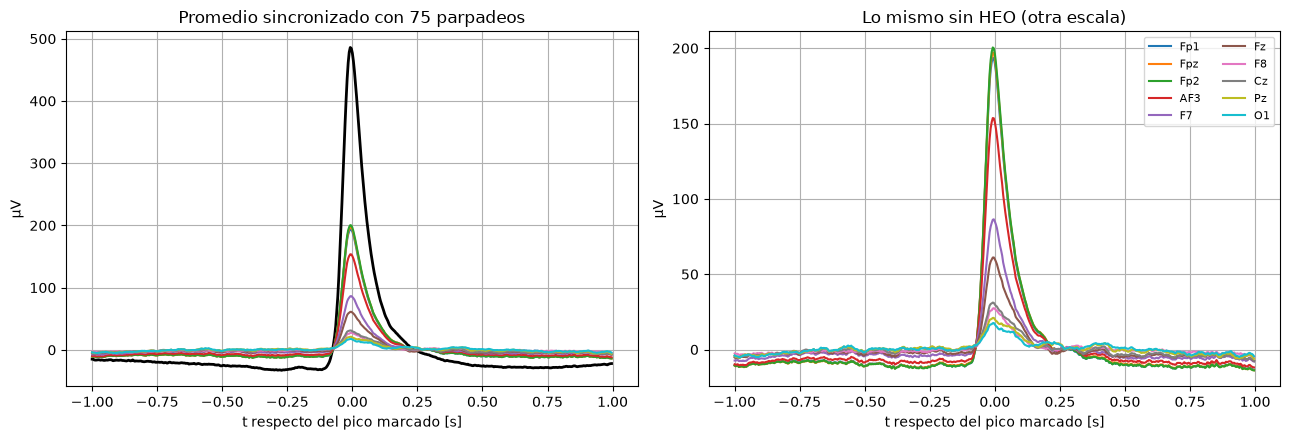

In [5]:
VENTANA = int(1 * FS)                              # ±1 s alrededor de cada parpadeo
tau = np.arange(-VENTANA, VENTANA) / FS


def promedio_sincronizado(x, picos):
    """Promedio de x en ventanas de ±VENTANA alrededor de cada pico."""
    tramos = [x[k - VENTANA:k + VENTANA] for k in picos if VENTANA <= k < len(x) - VENTANA]
    return np.mean(tramos, axis=0)


CANALES_PROM = ["Fp1", "Fpz", "Fp2", "AF3", "F7", "Fz", "F8", "Cz", "Pz", "O1"]   # De adelante hacia atrás

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].plot(tau, promedio_sincronizado(DATOS[CANAL_EOG], PARPADEOS), "k", lw=2, label=CANAL_EOG)
for n in CANALES_PROM:
    axs[0].plot(tau, promedio_sincronizado(DATOS[n], PARPADEOS), label=n)
    axs[1].plot(tau, promedio_sincronizado(DATOS[n], PARPADEOS), label=n)
axs[0].set_title(f"Promedio sincronizado con {len(PARPADEOS)} parpadeos")
axs[1].set_title("Lo mismo sin HEO (otra escala)")
for ax in axs:
    ax.set_xlabel("t respecto del pico marcado [s]")
    ax.set_ylabel("µV")
    ax.grid(True)
axs[1].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

### Qué mirar: el parpadeo promedio
- **Tamaños de pico:**
  - `HEO`: 485 µV;
  - `Fp1`, `Fpz`, `Fp2`: ~200 µV;
  - `AF3`: ~150 µV; `F7`: ~85 µV; `Fz`: ~60 µV;
  - atrás (`Cz`, `Pz`, `O1`): 15–30 µV.
- **El pico cae en el mismo instante en todos los canales** (t ≈ 0): el camino ojo→electrodo no tiene retardo visible. Es lo esperable para un campo eléctrico, que a estas distancias llega instantáneamente.
- **La forma es la misma en todos:** un pulso de ~0.2 s con una cola hasta ~0.25 s. Solo cambia el tamaño. Eso es justamente el modelo `y = s + λ·η_EOG`: cada canal recibe una copia escalada.
- **El nivel antes y después del pico no es real** (−25 µV en `HEO`). Lo agrega el pasa-altos de 0.5 Hz, que a un pulso grande le pone lóbulos negativos a los costados. Está igual en `y` y en `x`, así que no cambia la relación entre ellas.

### 2.4 Mapa de λ
Divide el parpadeo promedio de cada canal por el de `HEO`, en el instante del pico. Ese cociente estima **`λ`**: qué fracción del parpadeo de la referencia llega a ese electrodo.

El mapa lo dibuja sobre la cabeza, vista desde arriba con la nariz hacia arriba. `CB1` y `CB2` quedan afuera porque no están en el montaje estándar de MNE.

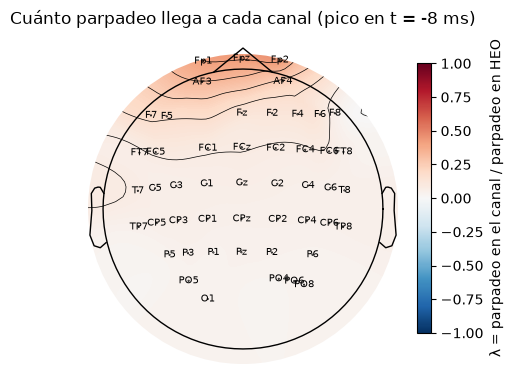

λ más grandes:
 Fp2    0.41
Fpz    0.41
Fp1    0.40
AF3    0.32
AF4    0.23
F7     0.18
F5     0.17
Fz     0.13

λ de algunos posteriores:
 Cz     0.06
Pz     0.04
P3     0.04
PO4    0.03
O1     0.04


In [6]:
prom_eog = promedio_sincronizado(DATOS[CANAL_EOG], PARPADEOS)
k_pico = np.argmax(np.abs(prom_eog))               # Muestra del pico del parpadeo promedio en HEO
LAMBDA = pd.Series({n: promedio_sincronizado(DATOS[n], PARPADEOS)[k_pico] / prom_eog[k_pico]
                    for n in CANALES_BUENOS})      # λ estimado: amplitud en el canal / amplitud en HEO

canales_mapa = [n for n in CANALES_BUENOS if n not in ["CB1", "CB2"]]   # CB1/CB2 no están en el montaje estándar
info = mne.create_info(canales_mapa, FS, "eeg")
info.set_montage("standard_1005")

fig, ax = plt.subplots(figsize=(5, 5))
im, _ = mne.viz.plot_topomap(LAMBDA[canales_mapa].values, info, axes=ax, show=False, cmap="RdBu_r",
                             vlim=(-1, 1), names=canales_mapa)
fig.colorbar(im, ax=ax, shrink=0.7, label="λ = parpadeo en el canal / parpadeo en HEO")
ax.set_title(f"Cuánto parpadeo llega a cada canal (pico en t = {tau[k_pico]*1000:.0f} ms)")
plt.show()

print("λ más grandes:\n", LAMBDA.sort_values(ascending=False).head(8).round(2).to_string())
print("\nλ de algunos posteriores:\n", LAMBDA[["Cz", "Pz", "P3", "PO4", "O1"]].round(2).to_string())

### Qué mirar: el mapa de λ
- **Adelante:** `λ ≈ 0.4` en `Fp1`, `Fpz` y `Fp2`; 0.32 en `AF3`, 0.23 en `AF4`, ~0.18 en `F7`/`F5`, 0.13 en `Fz`.
- **Atrás:** `λ ≈ 0.03–0.06` (`Cz`, `Pz`, `P3`, `PO4`, `O1`). Les llega ~5 % del parpadeo de `HEO`, o sea ~20 µV.
- **El mapa es un gradiente de adelante hacia atrás, simétrico entre izquierda y derecha.** Así se ve un parpadeo: los dos ojos a la vez, en el medio.
- **Consecuencia práctica:**
  - `Fp1` y `Fp2` son los mejores candidatos para `y`: es donde más ruido hay que sacar;
  - `Pz` sirve de control, porque casi no le llega.

### 2.5 ¿El camino ojo→electrodo tiene retardo? (decide M)
Para cada parpadeo calcula la correlación cruzada normalizada entre `HEO` y un canal en ±1 s, y después promedia sobre los parpadeos.
- **Si el máximo está en lag 0,** el canal ve el parpadeo al mismo tiempo que `HEO`, y alcanza con un filtro muy corto: en el límite `M = 1`, que es una ganancia.
- **Si el máximo estuviera corrido,** haría falta un `M` más grande para cubrir ese retardo.

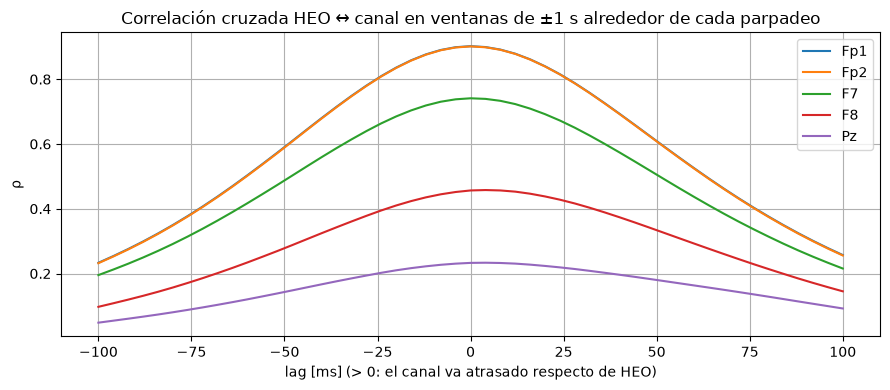

     lag del máximo [ms]  ρ(0)  ρ máx
Fp1                  0.0  0.90   0.90
Fp2                  0.0  0.90   0.90
F7                   0.0  0.74   0.74
F8                   4.0  0.46   0.46
Pz                   4.0  0.23   0.23


In [7]:
LAG_MAX = int(0.1 * FS)                            # ±100 ms
lags = np.arange(-LAG_MAX, LAG_MAX + 1)


def correlacion_cruzada(a, b, picos):
    """Correlación cruzada normalizada entre a y b en cada ventana de parpadeo, promediada. Lag > 0: b atrasada."""
    rho = []
    for k in picos:
        if not VENTANA <= k < len(a) - VENTANA:
            continue
        ta, tb = a[k - VENTANA:k + VENTANA], b[k - VENTANA:k + VENTANA]
        ta, tb = ta - ta.mean(), tb - tb.mean()
        c = correlate(tb, ta, mode="full") / (np.linalg.norm(ta) * np.linalg.norm(tb))
        rho.append(c[len(ta) - 1 - LAG_MAX:len(ta) + LAG_MAX])
    return np.mean(rho, axis=0)


filas = {}
fig, ax = plt.subplots(figsize=(9, 4))
for n in ["Fp1", "Fp2", "F7", "F8", "Pz"]:
    rho = correlacion_cruzada(DATOS[CANAL_EOG], DATOS[n], PARPADEOS)
    ax.plot(lags / FS * 1000, rho, label=n)
    filas[n] = {"lag del máximo [ms]": lags[np.argmax(np.abs(rho))] / FS * 1000, "ρ(0)": rho[LAG_MAX],
                "ρ máx": rho[np.argmax(np.abs(rho))]}
ax.set_xlabel("lag [ms] (> 0: el canal va atrasado respecto de HEO)")
ax.set_ylabel("ρ")
ax.set_title("Correlación cruzada HEO ↔ canal en ventanas de ±1 s alrededor de cada parpadeo")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()
print(pd.DataFrame(filas).T.round(2).to_string())

### Qué mirar: correlación cruzada
- **No hay retardo:** el máximo está en 0 ms para `Fp1`, `Fp2` y `F7`, y en 4 ms (1 muestra) para `F8` y `Pz`. El camino es casi una ganancia pura.
- **ρ(0) = 0.90 en `Fp1` y `Fp2`.** Durante los parpadeos, `HEO` explica el 81 % (ρ²) de la potencia de `Fp1`. Baja a 0.74 en `F7`, 0.46 en `F8` y 0.23 en `Pz`.
- **Las curvas son anchas** (recién caen a ±100 ms) porque el parpadeo es lento comparado con la muestra (4 ms). No es retardo.
- **Para el filtro:** `M = 3` (el valor de antes, He et al. 2004) alcanza de sobra. Lo mantenemos para comparar con el dataset anterior. Si queda corto o largo, se ve con un barrido.

### 2.6 PSD
Densidad espectral de potencia (Welch, ventanas de 2 s) de `HEO`, `Fp1`, `Pz` y `T7`, en todo el recorte. Las líneas punteadas son los límites de las bandas: δ|θ (4 Hz), θ|α (8), α|β (13) y β|γ (30).

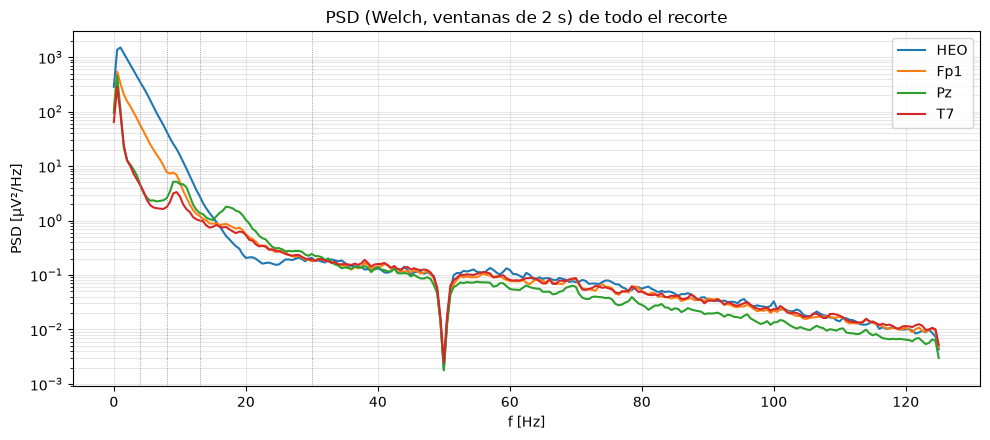

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for n in [CANAL_EOG, "Fp1", "Pz", "T7"]:
    f, P = welch(DATOS[n], FS, nperseg=2 * FS)
    ax.semilogy(f, P, label=n)
for f_b, nombre in [(4, "δ|θ"), (8, "θ|α"), (13, "α|β"), (30, "β|γ")]:
    ax.axvline(f_b, color="gray", lw=0.6, ls=":")
ax.set_xlabel("f [Hz]")
ax.set_ylabel("PSD [µV²/Hz]")
ax.set_title("PSD (Welch, ventanas de 2 s) de todo el recorte")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

### Qué mirar: PSD
- **`HEO` tiene casi toda su potencia por debajo de ~10 Hz:** entre 1 y 5 Hz, 100 veces más que el EEG. Es justo donde están δ y θ del EEG. Por eso no sirve un pasa-altos y hace falta la cancelación adaptativa.
- **`Pz` y `T7` tienen un pico en ~10 Hz (α) y otro en ~18 Hz** (β, típico de la corteza motora). `Fp1` tiene menos α. Esas son las partes del EEG que el filtro **no** tiene que tocar.
- **En 50 Hz hay un pozo, no un pico:** la línea ya viene filtrada con un notch. No sabíamos qué filtros traía el `.bdf`; ahora sabemos que al menos este. No hace falta agregar un notch.
- **No hay EMG evidente.** Arriba de ~25 Hz los cuatro canales tienen la misma PSD, incluso `HEO`, y `T7` (un temporal, cerca de los músculos de la mandíbula) no muestra potencia extra.

### 2.7 ¿HEO trae algo más que parpadeo? (fuga de EEG en la referencia)
Este es el riesgo del método (notebook anterior, §1.3): si la referencia trae EEG, el filtro lo puede restar.

La celda mide la correlación entre `HEO` y cada canal en 0.5–15 Hz, **por separado**:
- en las ventanas de parpadeo (±0.5 s alrededor de cada marca);
- en el resto.

Si fuera de los parpadeos la correlación es ~0, `HEO` no comparte EEG con los canales, y el filtro no tiene de dónde restar EEG bueno.

In [9]:
MARGEN = int(0.5 * FS)                             # Margen alrededor de cada parpadeo [muestras]
con_parpadeo = np.zeros(N_MUESTRAS, bool)
for k in PARPADEOS:
    con_parpadeo[max(k - MARGEN, 0):k + MARGEN] = True
limpio = ~con_parpadeo                             # Muestras a más de 0.5 s de cualquier parpadeo

sos_lp15 = butter(4, 15, "low", fs=FS, output="sos")
eog_lp = sosfiltfilt(sos_lp15, DATOS[CANAL_EOG])
corr_fuera = pd.Series({n: np.corrcoef(eog_lp[limpio], sosfiltfilt(sos_lp15, DATOS[n])[limpio])[0, 1]
                        for n in CANALES_BUENOS + ["M1", "M2"]})
corr_dentro = pd.Series({n: np.corrcoef(eog_lp[con_parpadeo], sosfiltfilt(sos_lp15, DATOS[n])[con_parpadeo])[0, 1]
                         for n in CANALES_BUENOS + ["M1", "M2"]})
fuga = pd.DataFrame({"ρ con parpadeos": corr_dentro, "ρ sin parpadeos": corr_fuera})

print(f"Muestras sin parpadeo (±{MARGEN / FS} s): {limpio.mean() * 100:.0f} %\n")
print("Correlación HEO ↔ canal (0.5-15 Hz):")
print(fuga.loc[["Fp1", "Fp2", "F7", "F8", "Fz", "Cz", "Pz", "O1", "T7", "T8", "M1", "M2"]].round(2).to_string())
print(f"\nMediana en los {len(CANALES_BUENOS)} canales buenos: con parpadeos {corr_dentro[CANALES_BUENOS].median():.2f}, "
      f"sin parpadeos {corr_fuera[CANALES_BUENOS].median():.2f}")

Muestras sin parpadeo (±0.5 s): 78 %

Correlación HEO ↔ canal (0.5-15 Hz):
     ρ con parpadeos  ρ sin parpadeos
Fp1             0.92             0.17
Fp2             0.92             0.15
F7              0.72             0.00
F8              0.40            -0.05
Fz              0.67             0.09
Cz              0.30             0.04
Pz              0.17            -0.04
O1              0.14            -0.08
T7              0.42            -0.08
T8              0.38            -0.04
M1              0.08            -0.00
M2             -0.06            -0.11

Mediana en los 51 canales buenos: con parpadeos 0.34, sin parpadeos -0.03


### Qué mirar: fuga de EEG en HEO
- **Con parpadeos, ρ es alta adelante:** 0.92 en `Fp1`/`Fp2`, 0.72 en `F7`. Baja hacia atrás: 0.17 en `Pz`, 0.14 en `O1`.
- **Sin parpadeos, ρ ≈ 0:** la mediana sobre los 51 canales buenos es −0.03. Solo `Fp1` y `Fp2` quedan en 0.15–0.17 (un poco de movimiento de ojos, o algo de EEG frontal que también ve `HEO`).
- **Conclusión:** fuera de los parpadeos `HEO` casi no se parece al EEG. Es una buena referencia: el filtro no debería poder restar mucho EEG.
- **El 78 % del tiempo no hay parpadeo** (con el margen de ±0.5 s). O sea, el filtro pasa la mayor parte del tiempo viendo una referencia que no tiene nada que ver con `y`. Eso importa en §3.

### 2.8 ¿Hay ruido que no sea de los ojos? (parte común)
En 2.2 vimos ondas lentas en todos los canales que no están en `HEO`. Para ver si son la misma señal en todos lados, la celda calcula la correlación entre canales en 0.5–3 Hz.
- Usa solo las muestras fuera de los parpadeos, para que el parpadeo no infle la correlación.
- Incluye canales de adelante, del medio, de los costados y de atrás, más `HEO`, `M1` y `M2`.

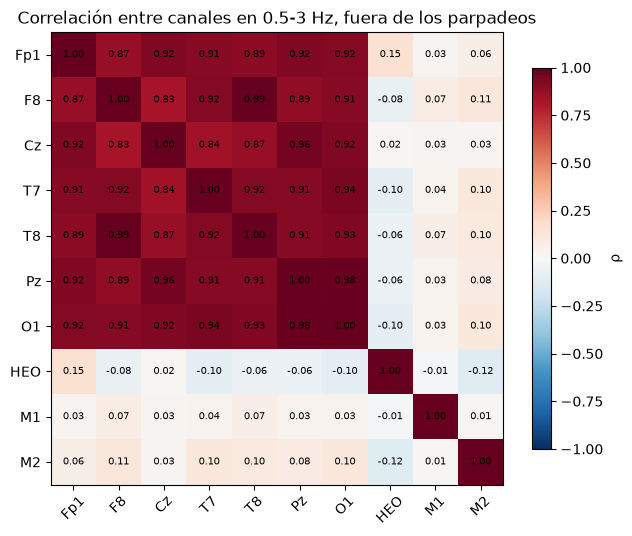

std de la parte común (promedio de los 51 buenos): 20.3 µV; std de Pz: 25.6 µV
Fracción de la potencia de Pz que explica la parte común: 91 %


In [10]:
sos_lp3 = butter(4, 3, "low", fs=FS, output="sos")
CANALES_COMUN = ["Fp1", "F8", "Cz", "T7", "T8", "Pz", "O1", CANAL_EOG, "M1", "M2"]
lentos = pd.DataFrame({n: sosfiltfilt(sos_lp3, DATOS[n])[limpio] for n in CANALES_COMUN})   # 0.5-3 Hz, sin parpadeos

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(lentos.corr().values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(CANALES_COMUN)), CANALES_COMUN, rotation=45)
ax.set_yticks(range(len(CANALES_COMUN)), CANALES_COMUN)
for i in range(len(CANALES_COMUN)):
    for j in range(len(CANALES_COMUN)):
        ax.text(j, i, f"{lentos.corr().values[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8, label="ρ")
ax.set_title("Correlación entre canales en 0.5-3 Hz, fuera de los parpadeos")
plt.tight_layout()
plt.show()

comun = np.mean([DATOS[n] for n in CANALES_BUENOS], axis=0)   # Promedio de los canales buenos
print(f"std de la parte común (promedio de los {len(CANALES_BUENOS)} buenos): {comun.std():.1f} µV; "
      f"std de Pz: {DATOS['Pz'].std():.1f} µV")
print(f"Fracción de la potencia de Pz que explica la parte común: "
      f"{np.corrcoef(comun, DATOS['Pz'])[0, 1]**2 * 100:.0f} %")

### Qué mirar: la parte común
- **Todos los canales de EEG se parecen entre sí casi por completo: ρ = 0.83 a 0.96.** Pasa entre `Fp1` (adelante) y `O1` (atrás), y entre `T7` y `T8` (izquierda y derecha). La actividad del cerebro no hace eso: canales a 20 cm deberían parecerse mucho menos.
- **`HEO`, `M1` y `M2` no participan:** ρ ≈ 0 con todos.
- **El promedio de los 51 canales buenos explica el 91 % de la potencia de `Pz`.** Lo que mide `Pz` es casi todo esta parte común.
- **Hipótesis (no comprobada):**
  - Es algo que comparten todos los canales de EEG y no `HEO`. La explicación más simple es la **referencia**: todos los canales de EEG se miden contra el mismo electrodo, y si ese electrodo se mueve, el ruido aparece en todos. Encaja con que las ondas aparezcan sobre todo al mover el brazo.
  - `HEO` no tiene esta parte, así que probablemente se mide contra otra referencia; por ejemplo, bipolar (un electrodo contra otro, los dos cerca del ojo).
- **Para el filtro:** esta parte común es **ruido en `y` que no está en `x`**. El filtro no tiene con qué armarla, así que no la puede sacar y va a quedar en `e`. Para el filtro funciona como si fuera EEG: hace más grande `J_min`.

### 2.9 Cuánta señal hay sin parpadeos
Cuenta los tramos seguidos sin parpadeo (a más de 0.5 s de cualquier marca) y cuántas ventanas de 1, 2, 4 y 8 s entran en ellos sin superponerse.

Todavía no lo usamos. Es lo que habría disponible para un experimento semi-sintético como el de §4 del notebook anterior: EEG "limpio" más el parpadeo de otro momento.

In [11]:
# Tramos seguidos sin parpadeo
bordes = np.flatnonzero(np.diff(np.r_[0, limpio.astype(int), 0]))
largos = (bordes[1::2] - bordes[0::2]) / FS        # Duración de cada tramo limpio [s]

filas = {L: {"ventanas sin parpadeo": int(np.sum(np.floor(largos / L))),
             "segundos que cubren": int(np.sum(np.floor(largos / L)) * L)} for L in [1, 2, 4, 8]}
print(pd.DataFrame(filas).T.rename_axis("largo [s]").to_string())
print(f"\nTramos limpios: {len(largos)}, mediana {np.median(largos):.1f} s, máximo {largos.max():.1f} s")
print(f"Tiempo entre parpadeos: mediana {np.median(np.diff(PARPADEOS)) / FS:.1f} s")

           ventanas sin parpadeo  segundos que cubren
largo [s]                                            
1                            223                  223
2                             91                  182
4                             24                   96
8                              1                    8

Tramos limpios: 75, mediana 3.2 s, máximo 9.2 s
Tiempo entre parpadeos: mediana 4.2 s


### Qué mirar: ventanas sin parpadeo
- **Hay 75 tramos limpios**, de 3.2 s de mediana; el más largo dura 9.2 s. El tiempo típico entre parpadeos es 4.2 s.
- **Ventanas que entran:** 223 de 1 s, 91 de 2 s, 24 de 4 s y 1 de 8 s. En el notebook anterior las realizaciones del Monte Carlo eran de 20 s: acá no hay ni una.
- **Si hacemos semi-sintético,** va a tener que ser con ventanas cortas (2 s = 500 muestras), y el filtro tiene que converger en ese tiempo. Además, por 2.8, ese "EEG limpio" lleva adentro la parte común.

### 2.10 ¿La tarea motora mete ruido?
Desvío de algunos canales en cada fase de la tarea, usando solo las muestras sin parpadeo para que los parpadeos no lo inflen.
- **`std T7 > 30 Hz`** es el desvío arriba de 30 Hz en un temporal. Si la persona apretara la mandíbula o tensara el cuello en alguna fase, subiría.
- **La última columna** son los parpadeos por minuto en cada fase.

In [12]:
sos_hp30 = butter(4, 30, "high", fs=FS, output="sos")
filas = {}
for fase in ["otra", "fijación", "ejecución", "descanso"]:
    m = (FASE == fase) & limpio                    # Solo muestras de esa fase y sin parpadeo
    filas[fase] = {"segundos": m.sum() / FS}
    for n in ["Fp1", "Pz", "C3", "C4", "T7"]:
        filas[fase][f"std {n}"] = DATOS[n][m].std()
    filas[fase]["std T7 > 30 Hz"] = sosfiltfilt(sos_hp30, DATOS["T7"])[m].std()
    filas[fase]["parpadeos/min"] = np.sum(FASE[PARPADEOS] == fase) / (np.sum(FASE == fase) / FS) * 60
print("std [µV] por fase, sin las ventanas de parpadeo:")
print(pd.DataFrame(filas).T.round(1).to_string())

std [µV] por fase, sin las ventanas de parpadeo:
           segundos  std Fp1  std Pz  std C3  std C4  std T7  std T7 > 30 Hz  parpadeos/min
otra           19.4     27.4    34.0    29.7    19.7    27.2             3.0            8.0
fijación       72.3     18.0    20.1    18.6    14.2    17.0             2.8            9.0
ejecución     131.3     24.2    27.7    24.1    18.7    21.2             2.2           14.0
descanso       38.8     18.9    20.2    17.5    17.0    15.4             2.0           20.3


### Qué mirar: desvío por fase
- **Durante la ejecución el desvío sube ~30–40 %** respecto de la fijación: `Fp1` 24 contra 18 µV, `Pz` 28 contra 20 µV, `C3` 24 contra 19 µV. Encaja con las ondas lentas de 2.2, que aparecen al mover el brazo.
  - Ojo: también hay cambios reales del EEG al mover la mano (en `C3`/`C4` baja el ritmo μ), pero son más chicos y en 8–30 Hz.
- **Arriba de 30 Hz no cambia:** 2–3 µV en todas las fases. No hay EMG durante la tarea.
- **"otra" es la más ruidosa** (`Pz` 34 µV), en los ~19 s de bienvenida.
- **Los parpadeos se concentran en el descanso:** 20 por minuto, contra 9 en la fijación. La persona parpadea cuando la tarea se lo permite.

### Conclusiones de §2

**Lo que medimos:**

| Pregunta | Respuesta |
|---|---|
| Canales | 62 de EEG (51 buenos), `HEO`, y `M1`/`M2` raros (10–20 veces el EEG). Sin EOG vertical ni EMG. |
| Parpadeos | 75 en 336 s, marcados en `Blinks` y bien alineados. ~485 µV en `HEO`, ~200 µV en `Fp1`/`Fp2`. |
| `λ` | 0.4 en `Fp1`/`Fpz`/`Fp2`, 0.13–0.3 en el resto de los frontales, ~0.04 atrás. |
| Retardo ojo→electrodo | 0 ms (≤ 1 muestra). |
| `HEO` como referencia | ρ = 0.9 con `Fp1` en los parpadeos y ≈ 0 fuera de ellos: casi sin fuga de EEG. |
| Frecuencias | El EOG está por debajo de 10 Hz, encima de δ/θ. El 50 Hz ya viene filtrado. Sin EMG visible. |
| Ruido que no es de los ojos | Una parte común a todos los canales de EEG (0.5–3 Hz, ρ ≈ 0.9 entre canales), más fuerte al mover el brazo. No está en `HEO`. |
| Señal sin parpadeos | 78 % del tiempo, pero en tramos cortos (mediana 3.2 s). |

**Decisiones que salen de acá, para §3:**
- `y`: `Fp1` y `Fp2`, que es adonde más parpadeo llega; `Pz` como control (`λ ≈ 0.04`).
- `x`: `HEO`, sin más procesamiento que el pasa-altos común.
- `M = 3`: alcanza de sobra, porque no hay retardo.
- Ni referencia de EMG ni notch: no hacen falta.

**Para discutir:** qué hacer con la parte común (2.8).

## §3. El filtro: NLMS con HEO como referencia

> **Dónde estamos:** ya sabemos qué hay en las señales. Ahora corremos el filtro.
> 1. Las funciones: las mismas del notebook anterior, sin cambios.
> 2. Chequeos de cordura: que el código haga lo que dice la teoría.
> 3. Primera corrida sobre los datos reales: `y` = `Fp1`, `Fp2` y `Pz` (control), `x` = `HEO`.
> 4. Pruebas sobre esa corrida: cómo se ve en el tiempo, qué hacen los coeficientes, si el parpadeo desaparece y si se daña el EEG fuera de los parpadeos.
>
> **No hay ground truth:** no sabemos cuál es el EEG limpio. Todo lo de 3.3 en adelante son pruebas indirectas, como en §6 del notebook anterior.

### 3.1 Funciones
Copiadas tal cual de `proyecto1_g4.ipynb`, §3:
- **`armar_regresor(refs, n, M)`:** arma `x(n)` apilando los últimos `M` valores de cada referencia. Con una sola referencia es `[HEO(n), HEO(n−1), HEO(n−2)]`.
- **`nlms(y, refs, M, mu_t, delta)`:** la fórmula de `7. Variantes de LMS.pdf`, `w(n+1) = w(n) + μ̃ x(n) e*(n) / (‖x(n)‖² + δ)`. Devuelve `e`, `ŷ` y la historia de `w`.
- **`matriz_regresores`, `wiener`:** la solución de Wiener `w_o = R⁻¹p` estimada con promedios temporales. También da `J_min`, los autovalores de `R` y el spread `λmax/λmin`.
- **`aportes`:** qué parte de `ŷ` arma cada referencia.
- **`rrmse`, `rrmse_espectral`:** el error relativo `RMS(a−b)/RMS(b)`, en el tiempo y sobre la PSD.

In [13]:
def armar_regresor(refs, n, M):
    """x(n) = [x1(n), ..., x1(n-M+1), x2(n), ..., x2(n-M+1), ...]^T (ceros antes de n = 0)."""
    x = np.zeros(len(refs) * M)                      # Vector de entrada apilado, largo K*M
    for k, r in enumerate(refs):                     # Recorre cada referencia x_k
        for i in range(M):                           # Recorre los retardos 0, ..., M-1
            if n - i >= 0:                           # Antes de n = 0 la señal vale 0
                x[k * M + i] = r[n - i]              # x_k(n-i) en su lugar del vector apilado
    return x                                         # Devuelve x(n)


def nlms(y, refs, M, mu_t, delta):
    """
    NLMS con referencias apiladas.
    Devuelve:
        e: error (estimación del EEG limpio)
        y_hat: estimación del ruido en el electrodo
        W: W[n] = w(n), coeficientes usados en la muestra n
    """
    N = len(y)                                       # Cantidad de muestras
    w = np.zeros(len(refs) * M)                      # w(0) = 0
    W = np.zeros((N, len(refs) * M))                 # Historia de los coeficientes
    y_hat = np.zeros(N)                              # ŷ(n)
    e = np.zeros(N)                                  # e(n)
    for n in range(N):                               # Recorre las muestras
        x = armar_regresor(refs, n, M)               # Vector de entrada x(n)
        y_hat[n] = w @ x                             # ŷ(n) = w^H(n) x(n) (señales reales: w^H = w^T)
        e[n] = y[n] - y_hat[n]                       # e(n) = y(n) - ŷ(n)
        W[n] = w                                     # Guarda w(n)
        w = w + mu_t * x * e[n] / (x @ x + delta)    # w(n+1) = w(n) + μ̃ x(n) e*(n) / (||x(n)||² + δ)
    return e, y_hat, W


def matriz_regresores(refs, M):
    """Matriz N x (K*M) cuya fila n es x(n)^T."""
    N = len(refs[0])
    X = np.zeros((N, len(refs) * M))
    for k, r in enumerate(refs):
        for i in range(M):
            X[i:, k * M + i] = r[:N - i]
    return X


def wiener(y, refs, M):
    """Solución de Wiener estimada con promedios temporales."""
    X = matriz_regresores(refs, M)
    R = X.T @ X / len(y)                             # R = E{x x^T}
    p = X.T @ y / len(y)                             # p = E{x y}
    w_o = np.linalg.solve(R, p)                      # w_o = R^-1 p
    lam = np.linalg.eigvalsh(R)
    return {"w_o": w_o, "J_min": np.mean((y - X @ w_o)**2), "autovalores": lam,
            "spread": lam.max() / lam.min(), "P_x": np.trace(R)}


def aportes(refs, W, M):
    """Parte de ŷ que arma cada referencia: ŷ_k(n) = w_k(n)^T x_k(n)."""
    X = matriz_regresores(refs, M)
    return [np.sum(W[:, k * M:(k + 1) * M] * X[:, k * M:(k + 1) * M], axis=1) for k in range(len(refs))]


def rrmse(a, b):
    return np.sqrt(np.mean((a - b)**2) / np.mean(b**2))


def rrmse_espectral(a, b):
    _, Pa = welch(a, FS, nperseg=FS)
    _, Pb = welch(b, FS, nperseg=FS)
    return rrmse(Pa, Pb)

### 3.2 Chequeos de cordura
Antes de creerle al filtro sobre datos reales, tres pruebas donde sabemos la respuesta:
- **(a) Caso de libro:** referencia de ruido blanco e `y = s + h ∗ x`, con `h = [0.8, −0.3, 0.1]` conocido. `w(N)` tiene que llegar a `w_o ≈ h`.
- **(b) Lo mismo, pero con el `HEO` real como referencia** y `Pz` como `s`. La respuesta sigue siendo `h`, pero ahora `x` es pasa-bajos: el spread de `R` es grande y los modos lentos tardan (`6. LMS.pdf`, Convergencia).
- **(c) μ̃ > 2 tiene que divergir** (`7. Variantes de LMS.pdf`, NLMS: estable para 0 < μ̃ < 2).

In [14]:
M = 3
rng = np.random.default_rng(0)

# (a) Caso de libro: referencia blanca, y = s + h * x  ->  w(N) tiene que llegar a w_o
N = 20000
x1 = rng.normal(size=N)
s = 0.1 * rng.normal(size=N)
y = s + lfilter([0.8, -0.3, 0.1], 1, x1)
_, _, W = nlms(y, [x1], M, 0.1, 1e-6)
print("(a) w(N) =", W[-1].round(3), "  w_o =", wiener(y, [x1], M)["w_o"].round(3), "  (h = [0.8, -0.3, 0.1])")

# (b) Con el HEO real como referencia y h conocido: tiene que llegar a h, pero más lento (spread)
x1 = DATOS[CANAL_EOG]
y = DATOS["Pz"] + lfilter([0.8, -0.3, 0.1], 1, x1)
_, _, W = nlms(y, [x1], M, 0.03, 1e-3 * M * np.mean(x1**2))
wi = wiener(y, [x1], M)
print(f"(b) HEO real: w(N) = {W[-1].round(3)}  w_o = {wi['w_o'].round(3)}  spread de R = {wi['spread']:.0f}")

# (c) μ̃ > 2 tiene que divergir
with np.errstate(all="ignore"):
    e, _, _ = nlms(y[:5000], [x1[:5000]], M, 2.5, 1e-3 * M * np.mean(x1**2))
print(f"(c) μ̃ = 2.5: max|e| en los últimos 1000 = {np.max(np.abs(e[-1000:])):.3g} µV  (enorme o nan: diverge)")

(a) w(N) = [ 0.776 -0.299  0.12 ]   w_o = [ 0.8   -0.3    0.099]   (h = [0.8, -0.3, 0.1])
(b) HEO real: w(N) = [ 0.352 -0.784 -0.097]  w_o = [ 0.798 -0.281  0.119]  spread de R = 2685
(c) μ̃ = 2.5: max|e| en los últimos 1000 = nan µV  (enorme o nan: diverge)


### Qué mirar: chequeos de cordura
- **(a) pasa:** `w(N) = [0.776, −0.299, 0.12]` contra `w_o = [0.8, −0.3, 0.099]`. El código está bien.
- **(b) no llega:**
  - `w(N) = [0.35, −0.78, −0.10]` contra `w_o = [0.80, −0.28, 0.12]`, con un spread de 2685 (en el dataset anterior, el EOG solo daba ~300).
  - La respuesta es la misma que en (a); lo único que cambió es la referencia. Aun así, después de 336 s el filtro no llegó a `w_o`.
- **(c) pasa:** diverge (`nan`).
- **Lo de (b) es lo primero para discutir:** con la referencia real, NLMS no llega a `w_o` ni siquiera con `h` conocido. Se vuelve a ver en 3.5.

### 3.3 Primera corrida sobre los datos reales
`procesar(canal)` corre NLMS con `y` = el canal y `x` = `HEO`, y calcula Wiener sobre la misma señal para comparar.

**Metaparámetros:**
- `M = 3`, por 2.5.
- `μ̃ = 0.03`. **Es el valor que elegimos con el dataset anterior, no está elegido para este.** Lo usamos como punto de partida; el barrido viene después de discutir.
- `δ = 10⁻³ · M · P_x`: solo para no dividir por ~0.

**Canales:** `Fp1` y `Fp2` (`λ ≈ 0.4`), y `Pz` como control (`λ ≈ 0.04`).

**Qué da la tabla:**
- `w(N)` (el último) comparado con `w_o`;
- `J_min/P_y`: qué fracción de la potencia de `y` no puede sacar ni el mejor filtro fijo;
- el spread de `R`;
- la correlación de `y` y de `e` con la referencia.

In [15]:
M = 3                       # Coeficientes por referencia (He et al. 2004)
MU_T = 0.03                 # Punto de partida: el valor elegido con el dataset anterior, todavía no barrido acá
DELTA_REL = 1e-3            # δ = DELTA_REL · M · P_x: solo evita dividir por ~0
CANALES_Y = ["Fp1", "Fp2", "Pz"]   # Los dos con más parpadeo y un control lejos de los ojos


def procesar(canal, mu_t=MU_T, M=M):
    """NLMS con y = canal y x = HEO, más la solución de Wiener para comparar."""
    y, refs = DATOS[canal], [DATOS[CANAL_EOG]]
    delta = DELTA_REL * M * np.mean(refs[0]**2)
    e, y_hat, W = nlms(y, refs, M, mu_t, delta)
    return {"y": y, "e": e, "y_hat": y_hat, "W": W, "wiener": wiener(y, refs, M)}


reales = {n: procesar(n) for n in CANALES_Y}

filas = {}
for n, r in reales.items():
    w_o = r["wiener"]["w_o"]
    filas[n] = {"w(N)": r["W"][-1].round(3), "w_o": w_o.round(3),
                "‖w(N)−w_o‖/‖w_o‖": np.linalg.norm(r["W"][-1] - w_o) / np.linalg.norm(w_o),
                "J_min / P_y": r["wiener"]["J_min"] / np.mean(r["y"]**2),
                "spread": r["wiener"]["spread"],
                "ρ(y, x)": np.corrcoef(r["y"], DATOS[CANAL_EOG])[0, 1],
                "ρ(e, x)": np.corrcoef(r["e"], DATOS[CANAL_EOG])[0, 1]}
print(pd.DataFrame(filas).T.to_string(float_format=lambda v: f"{v:.3g}"))

                         w(N)                     w_o ‖w(N)−w_o‖/‖w_o‖ J_min / P_y   spread ρ(y, x) ρ(e, x)
Fp1     [0.637, 0.451, 0.519]   [0.323, 0.041, 0.025]             2.19       0.433 2.68e+03   0.753  -0.132
Fp2      [0.589, 0.425, 0.53]   [0.328, 0.048, 0.024]             2.06       0.444 2.68e+03   0.745  -0.129
Pz   [-0.448, -0.484, -0.197]  [-0.002, 0.019, 0.019]               26       0.992 2.68e+03  0.0896 -0.0551


### Qué mirar: NLMS contra Wiener
- **Wiener, `Fp1` y `Fp2`:** `w_o ≈ [0.32, 0.04, 0.02]`. Casi todo está en el primer coeficiente, o sea, es una ganancia: la suma (≈ 0.39) se parece al `λ ≈ 0.4` del mapa de 2.4.
- **Wiener, `Pz`:** `w_o ≈ 0`.
- **`J_min/P_y`:**
  - 0.43 en `Fp1`: el mejor filtro fijo saca el 57 % de la potencia de `Fp1`;
  - 0.99 en `Pz`: no hay nada que sacar.

  Los dos encajan con 2.4.
- **NLMS no está cerca de `w_o`:**
  - `Fp1`: `w(N) = [0.64, 0.45, 0.52]`, a una distancia de 2.2 veces `‖w_o‖`;
  - `Pz`: `w(N) = [−0.45, −0.48, −0.20]`, cuando debería ser ~0 (a 26 veces `‖w_o‖`).
- **ρ(e, x) pasa de 0.75 a −0.13 en `Fp1`.** Sacó la mayor parte de lo correlacionado con `HEO`, pero queda negativa: restó de más. Con `w_o`, el principio de ortogonalidad dice que daría 0.
- **Ojo con `w(N)`:** es un solo instante. En 3.5 se ve que `w` cambia todo el tiempo, así que no hay que leerlo como "el valor al que llegó".

### 3.4 En el tiempo
Muestra 15 s (de 40 a 55 s) de `y`, `ŷ` y `e` en los tres canales, con los parpadeos marcados.

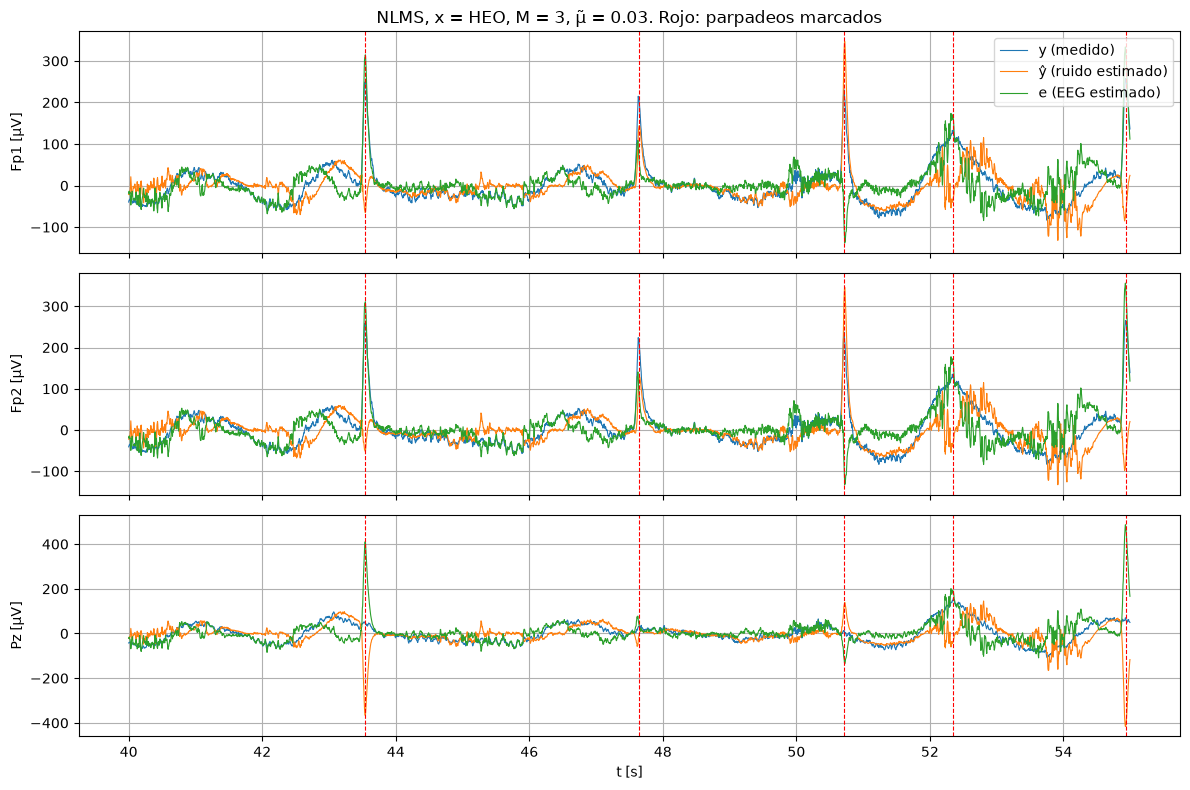

In [16]:
T_VER_3 = (40, 55)                                 # Tramo a mirar [s]
i0, i1 = [int((tv - T_INI) * FS) for tv in T_VER_3]

fig, axs = plt.subplots(len(CANALES_Y), 1, figsize=(12, 8), sharex=True)
for ax, (n, r) in zip(axs, reales.items()):
    ax.plot(t[i0:i1], r["y"][i0:i1], label="y (medido)", lw=0.8)
    ax.plot(t[i0:i1], r["y_hat"][i0:i1], label="ŷ (ruido estimado)", lw=0.8)
    ax.plot(t[i0:i1], r["e"][i0:i1], label="e (EEG estimado)", lw=0.8)
    for k in PARPADEOS[(PARPADEOS >= i0) & (PARPADEOS < i1)]:
        ax.axvline(t[k], color="r", lw=0.8, ls="--")
    ax.set_ylabel(f"{n} [µV]")
    ax.grid(True)
axs[0].legend(loc="upper right")
axs[0].set_title(f"NLMS, x = HEO, M = {M}, μ̃ = {MU_T}. Rojo: parpadeos marcados")
axs[-1].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

### Qué mirar: y, ŷ y e en el tiempo
- **En `Fp1` y `Fp2` los parpadeos se van.** Donde `y` tiene picos de 200–300 µV, `ŷ` los copia y `e` queda al nivel del resto.
- **Pero `ŷ` no es cero entre parpadeos:** tiene oscilaciones rápidas de hasta ±100 µV (por ejemplo, entre 52 y 55 s), y `e` las hereda con el signo opuesto. **Entre parpadeos el filtro agrega algo que no estaba en `y`.**
- **Las ondas lentas comunes de 2.8 quedan en `e`** (por ejemplo, 52–53 s). El filtro no las puede sacar porque no están en `HEO`.
- **En `Pz` el filtro empeora la señal:** en cada parpadeo, `ŷ` tiene un pico de −400 µV y `e` uno de +400 µV, cuando `y` tenía ~20 µV.

### 3.5 Los coeficientes en el tiempo
Muestra `w(n)` de los tres coeficientes para cada canal. En línea punteada del mismo color, el `w_o` de Wiener.

Si NLMS convergiera, cada línea se quedaría cerca de su punteada, con un ruido chico alrededor (el desajuste).

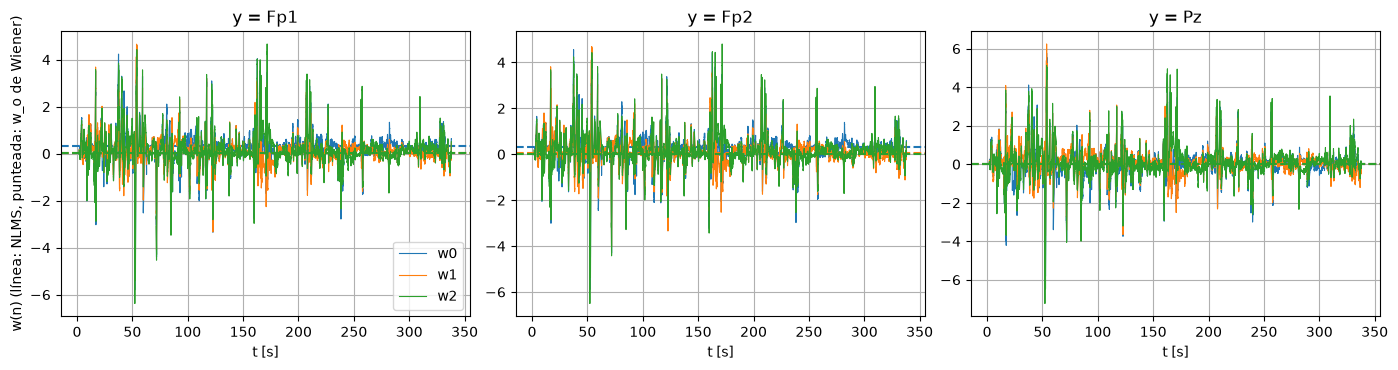

In [17]:
fig, axs = plt.subplots(1, len(CANALES_Y), figsize=(14, 3.8), sharex=True)
for ax, (n, r) in zip(axs, reales.items()):
    for i in range(M):
        linea, = ax.plot(t, r["W"][:, i], label=f"w{i}", lw=0.8)
        ax.axhline(r["wiener"]["w_o"][i], color=linea.get_color(), ls="--")
    ax.set_title(f"y = {n}")
    ax.set_xlabel("t [s]")
    ax.grid(True)
axs[0].set_ylabel("w(n) (línea: NLMS, punteada: w_o de Wiener)")
axs[0].legend()
plt.tight_layout()
plt.show()

### Qué mirar: los coeficientes
- **Los coeficientes saltan entre −6 y +5**, cuando `w_o` está entre 0 y 0.32. En ningún momento de los 336 s se quedan cerca de `w_o`. No es un transitorio inicial: pasa de principio a fin.
- **En `Pz` pasa lo mismo**, aunque ahí `w_o ≈ 0`.
- **Esto explica 3.4:** cuando llega un parpadeo y `w` está en un valor cualquiera, `ŷ = wᵀx` es ese valor multiplicado por 500 µV.
- **No es un error del código:** pasó el chequeo (a). Es lo que hace NLMS con esta referencia. Hay dos sospechosos, sin comprobar:
  1. el spread de 2685, que deja modos que casi no se corrigen;
  2. que NLMS divide por `‖x(n)‖²`, que **entre parpadeos es chico**. Entonces el paso efectivo `μ̃/‖x‖²` se hace enorme justo cuando `x` no trae parpadeo, y el filtro "aprende" del EEG que hay en `e`.

### 3.6 ¿Desaparece el parpadeo? (promedio sincronizado de y y e)
Esta es la prueba principal: el promedio sincronizado de 2.3, ahora sobre `y` y sobre `e`. Si el filtro saca el parpadeo, la curva de `e` tiene que quedar plana.

La tabla da el pico a pico de cada promedio y cuánto bajó, en dB.

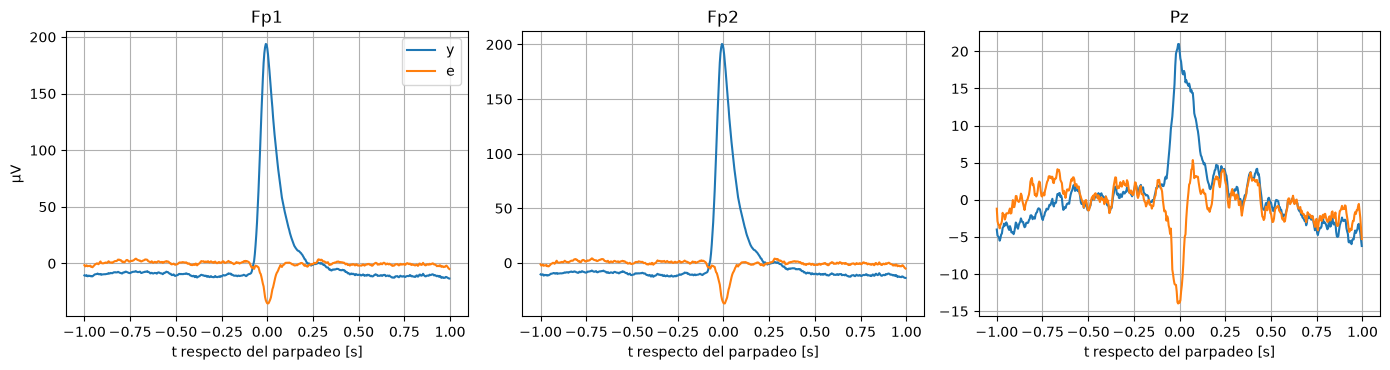

     pico a pico y [µV]  pico a pico e [µV]  reducción [dB]
Fp1               207.1                39.6           -14.4
Fp2               214.3                41.3           -14.3
Pz                 27.2                19.3            -3.0


In [18]:
fig, axs = plt.subplots(1, len(CANALES_Y), figsize=(14, 3.8))
filas = {}
for ax, (n, r) in zip(axs, reales.items()):
    py, pe = promedio_sincronizado(r["y"], PARPADEOS), promedio_sincronizado(r["e"], PARPADEOS)
    ax.plot(tau, py, label="y")
    ax.plot(tau, pe, label="e")
    ax.set_title(n)
    ax.set_xlabel("t respecto del parpadeo [s]")
    ax.grid(True)
    filas[n] = {"pico a pico y [µV]": np.ptp(py), "pico a pico e [µV]": np.ptp(pe),
                "reducción [dB]": 20 * np.log10(np.ptp(pe) / np.ptp(py))}
axs[0].set_ylabel("µV")
axs[0].legend()
plt.tight_layout()
plt.show()
print(pd.DataFrame(filas).T.round(1).to_string())

### Qué mirar: el parpadeo promedio en y y en e
- **En `Fp1` y `Fp2` el pico baja de ~210 a ~40 µV pico a pico (−14 dB).** Sacó la mayor parte del parpadeo.
- **Pero no queda plano: queda un pozo de ~−35 µV en t = 0.** El filtro restó de más en el pico, lo mismo que decía ρ(e, x) < 0 en 3.3. En el notebook anterior también restaba de más el EOG.
- **En `Pz` la curva se da vuelta:** `y` tenía +21 µV y `e` tiene −14 µV. El pico a pico baja solo 3 dB, y es porque cambió de signo, no porque el parpadeo se fue.

### 3.7 ¿Se daña el EEG fuera de los parpadeos?
Compara la potencia de `e` con la de `y`, en dB:
- **0 dB:** no cambió;
- **negativo:** el filtro sacó;
- **positivo:** el filtro agregó.

Se mide en tres lugares:
- 0.5–8 Hz **con** parpadeo, donde queremos que baje;
- 0.5–8 Hz **sin** parpadeo, donde queremos que no cambie;
- α (8–13 Hz) sin parpadeo: el EEG que menos queremos tocar.

La última columna es `RRMSE(e, y)` fuera de los parpadeos. Si el filtro no hace nada ahí, tiene que dar ~0.

In [19]:
sos_08 = butter(4, [F_HP, 8], "bandpass", fs=FS, output="sos")
sos_alfa = butter(4, [8, 13], "bandpass", fs=FS, output="sos")


def potencia(x, sos, mascara):
    """Potencia de x filtrada con sos, solo en las muestras de la máscara."""
    return np.mean(sosfiltfilt(sos, x)[mascara]**2)


def db(a, b):
    return 10 * np.log10(a / b)


filas = {}
for n, r in reales.items():
    filas[n] = {"0.5-8 Hz con parpadeo [dB]": db(potencia(r["e"], sos_08, con_parpadeo), potencia(r["y"], sos_08, con_parpadeo)),
                "0.5-8 Hz sin parpadeo [dB]": db(potencia(r["e"], sos_08, limpio), potencia(r["y"], sos_08, limpio)),
                "α sin parpadeo [dB]": db(potencia(r["e"], sos_alfa, limpio), potencia(r["y"], sos_alfa, limpio)),
                "RRMSE(e, y) sin parpadeo": rrmse(r["e"][limpio], r["y"][limpio])}
print("Cambio de potencia de e respecto de y (0 dB = no cambió; negativo = el filtro sacó):")
print(pd.DataFrame(filas).T.round(2).to_string())

Cambio de potencia de e respecto de y (0 dB = no cambió; negativo = el filtro sacó):
     0.5-8 Hz con parpadeo [dB]  0.5-8 Hz sin parpadeo [dB]  α sin parpadeo [dB]  RRMSE(e, y) sin parpadeo
Fp1                       -0.32                        0.77                 1.84                      0.86
Fp2                       -0.05                        1.10                 2.24                      0.86
Pz                        13.90                        2.62                 1.62                      0.87


### Qué mirar: daño al EEG
- **Con parpadeo, 0.5–8 Hz casi no baja (−0.3 dB en `Fp1`),** aunque el promedio bajó 14 dB. Una explicación posible: lo que el filtro saca del parpadeo lo devuelve como oscilaciones (3.4).
- **Sin parpadeo, la potencia sube:** +0.8 a +1.1 dB en 0.5–8 Hz, y **+1.8 a +2.2 dB en α**. El filtro **agrega** potencia donde no tendría que tocar nada.
- **`RRMSE(e, y)` sin parpadeo = 0.86:** fuera de los parpadeos, `e` es muy distinta de `y`. Un filtro que solo sacara parpadeos daría ~0.
- **En `Pz`, +13.9 dB con parpadeo:** confirma lo de 3.4, el filtro le mete parpadeos a un canal que casi no los tenía.

### Para discutir

**Lo que salió:**
- **El parpadeo se va del promedio** en `Fp1`/`Fp2` (−14 dB), pero deja un pozo de −35 µV: resta de más.
- **Fuera de los parpadeos el filtro agrega potencia** (+2 dB en α), y `e` difiere mucho de `y` (RRMSE 0.86).
- **Los coeficientes saltan de −6 a +5 todo el tiempo,** lejos de `w_o`. Ni siquiera con `h` conocido (chequeo (b)) llegan a `w_o`.
- **En `Pz` (el control) el filtro mete parpadeos.**

**Preguntas abiertas:**
1. **¿Por qué saltan los coeficientes?** ¿Es el spread (2685) o el paso efectivo `μ̃/‖x‖²` entre parpadeos? Se puede separar mirando cuánto saltan con `M = 1` (que no tiene spread) y con distintos `μ̃`.
2. **¿Qué `μ̃` y qué `M`?** `0.03` y `3` vienen del dataset anterior. Hace falta un barrido, pero ¿sobre qué métrica, si no hay ground truth?
3. **¿NLMS es la elección correcta acá?** Su argumento era "la potencia de `x` cambia mucho por los parpadeos y NLMS lo compensa". Pero acá la referencia pasa el 78 % del tiempo sin parpadeo.
4. **¿Qué hacemos con la parte común a todos los canales (2.8)?** ¿Se saca antes (por ejemplo, restando el promedio de todos los canales), se deja, o se usa como otra referencia?
5. **¿Hacemos semi-sintético?** Hay ventanas limpias de 1–2 s (2.9): cortas para que el filtro converja, y con la parte común adentro.
6. **¿Agregamos EMG?** En 2.6 y 2.10 no se ve EMG en este registro.